### 선형회귀(Linear regression)
- 입력과 출력간의 관계를 (선형으로 놓고) 알아내는 것
    - 광고비와 매출액의 관계
- 목적 : 최적의 기울기와 절편 구하기
    - 실제값과 예측값의 오차가 최소화 되게 구하는 게 목적
    - MSE 사용
- 경사하강법 사용

In [1]:
import torch
import matplotlib.pyplot as plt

In [ ]:
x = torch.tensor([150., 160, 170, 175, 185])
y = torch.tensor([55, 70, 64, 80, 75.])
N = len(x)

plt.plot(x, y, 'o')

In [ ]:
# 임의로 기울기와 절편 설정
a = 0.45    # 기울기
b = -35     # 절편

x_plot = torch.linspace(145, 190, 100)
y_plot = a * x_plot + b

plt.figure()
plt.plot(x,y,'o')           # 실제 키와 몸무게
plt.plot(x_plot, y_plot, 'r')   # 임의로 만든 선형

(0.0, 1000.0)

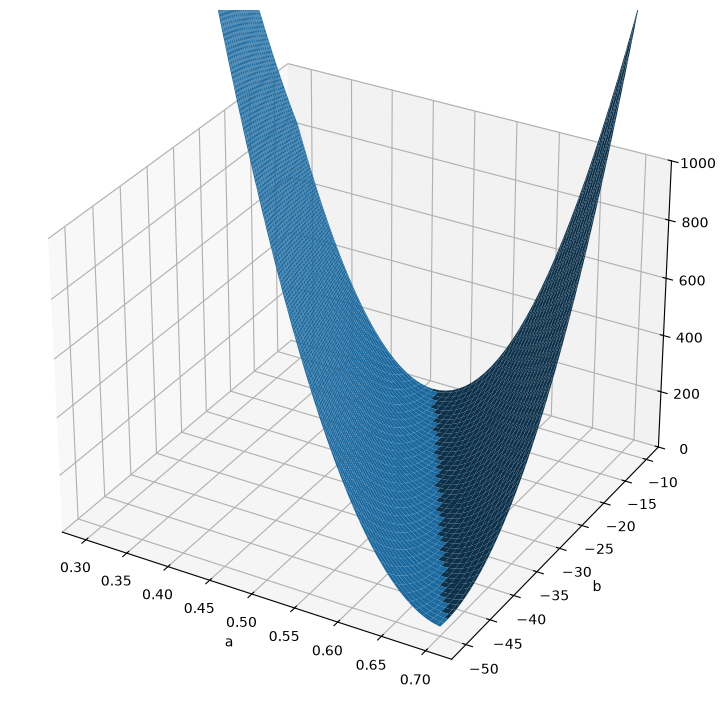

In [6]:
a = 0.5 + torch.linspace(-0.2, 0.2, 100)  # 0.3 ~ 0.7 기울기 후보군
b = -30 + torch.linspace(-20, 20, 100)  # -50 ~ -10  절편 후보군

L = torch.zeros(len(a), len(b))

for i in range(len(a)):
    for j in range(len(b)):
        for n in range(N) :
            L[i,j] = L[i,j] + (y[n] - (a[i]*x[n]+b[j]))**2

L = L/N # MSE

plt.figure(figsize = [10, 9])
ax = plt.axes(projection="3d")
A, B = torch.meshgrid(a,b, indexing='ij')

ax.plot_surface(A, B, L)
ax.set_xlabel('a')
ax.set_ylabel('b')
ax.set_zlim([0, 1000])

In [7]:
L

tensor([[4717.8999, 4662.7900, 4608.0068,  ...,  892.4518,  869.0127,
          845.8998],
        [4625.1914, 4570.6304, 4516.3955,  ...,  852.9494,  830.0588,
          807.4945],
        [4533.4097, 4479.3970, 4425.7109,  ...,  814.3732,  792.0311,
          770.0153],
        ...,
        [  37.8939,   35.9905,   34.4135,  ..., 1373.4280, 1403.1949,
         1433.2881],
        [  35.0339,   33.6789,   32.6504,  ..., 1423.7732, 1454.0889,
         1484.7303],
        [  33.1000,   32.2935,   31.8136,  ..., 1475.0457, 1505.9099,
         1537.1000]])

In [9]:
print(torch.min(L))
a_opt = A[L == torch.min(L)]
b_opt = B[L == torch.min(L)]

print(f'optimal a = {a_opt}')   # 기울기 최적
print(f'optimal b = {b_opt}')   # 절편 최적

tensor(29.0315)
optimal a = tensor([0.5626])
optimal b = tensor([-25.7576])


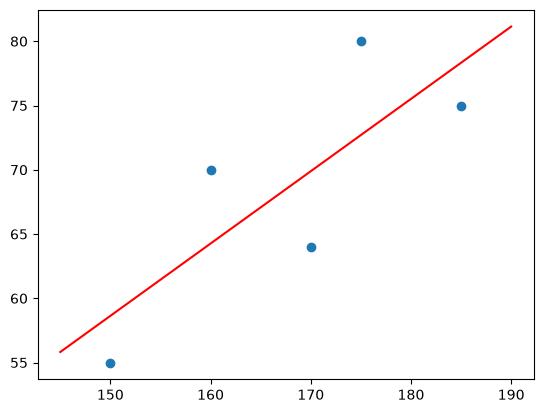

In [10]:
x_plot = torch.linspace(145, 190, 100)
y_plot = a_opt * x_plot + b_opt
plt.plot(x,y,'o')
plt.plot(x_plot, y_plot, 'r')

#### 경사하강법

Epoch : 1, train loss : 826.2250
Weight : 0.4785, Bias : -34.9998


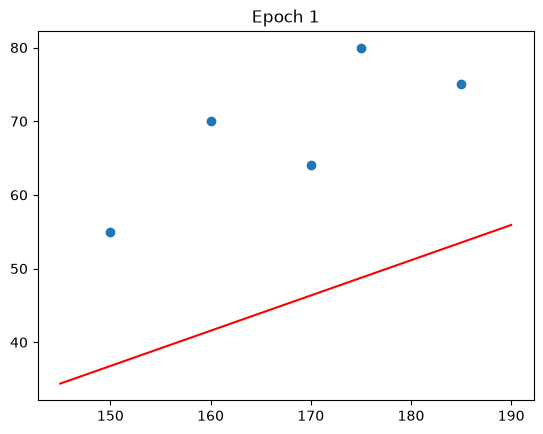

--------------------
Epoch : 2, train loss : 578.0414
Weight : 0.5022, Bias : -34.9997


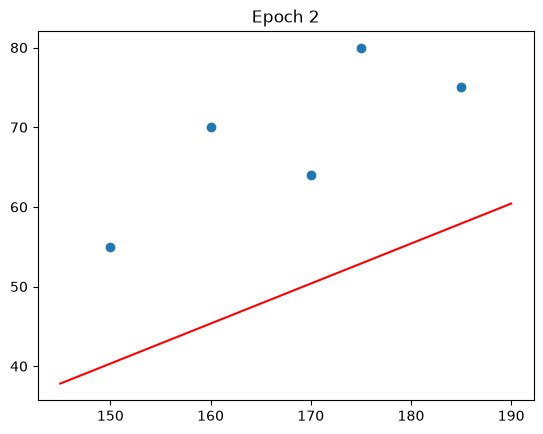

--------------------
Epoch : 3, train loss : 407.1602
Weight : 0.5218, Bias : -34.9996


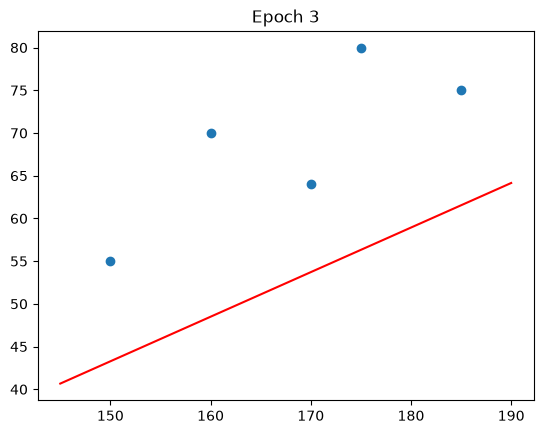

--------------------
Epoch : 4, train loss : 289.5042
Weight : 0.5381, Bias : -34.9995


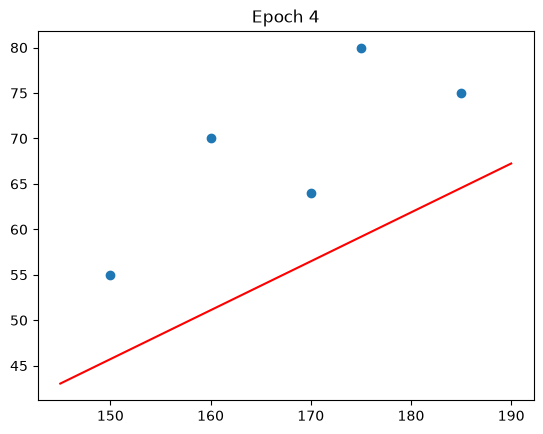

--------------------
Epoch : 5, train loss : 208.4954
Weight : 0.5517, Bias : -34.9994


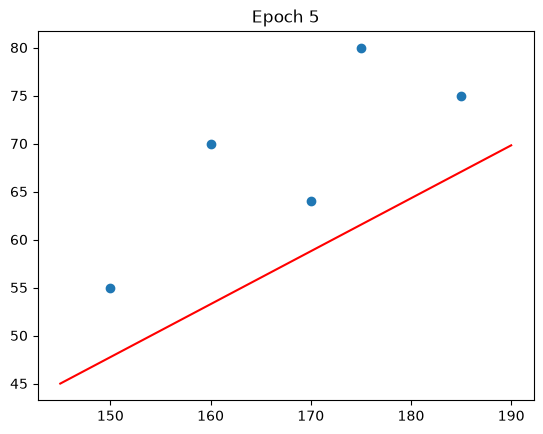

--------------------
Epoch : 6, train loss : 152.7187
Weight : 0.5629, Bias : -34.9993


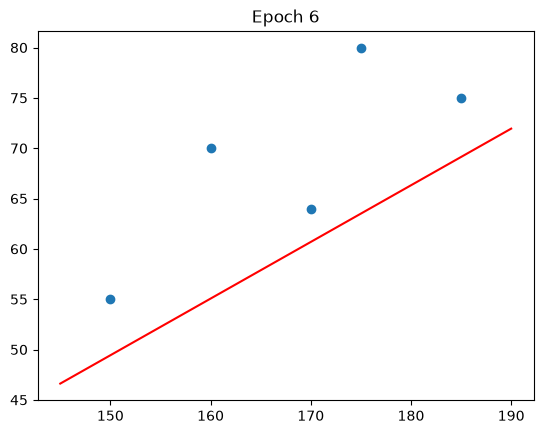

--------------------
Epoch : 7, train loss : 114.3153
Weight : 0.5722, Bias : -34.9993


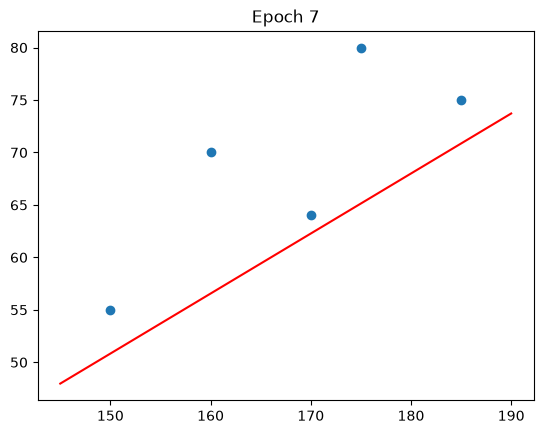

--------------------
Epoch : 8, train loss : 87.8735
Weight : 0.5799, Bias : -34.9992


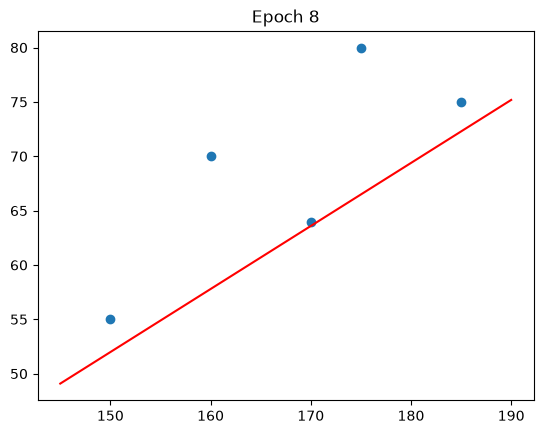

--------------------
Epoch : 9, train loss : 69.6676
Weight : 0.5863, Bias : -34.9992


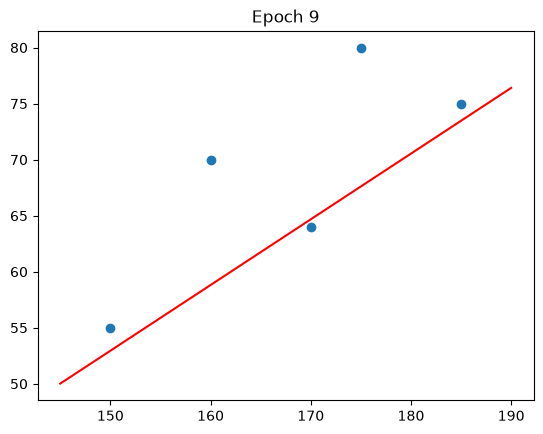

--------------------
Epoch : 10, train loss : 57.1324
Weight : 0.5917, Bias : -34.9992


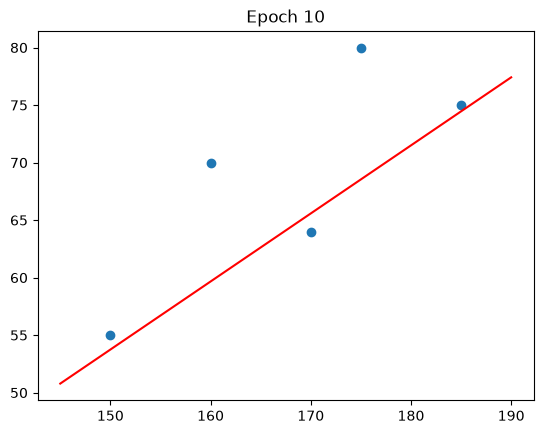

--------------------
Epoch : 11, train loss : 48.5017
Weight : 0.5961, Bias : -34.9991


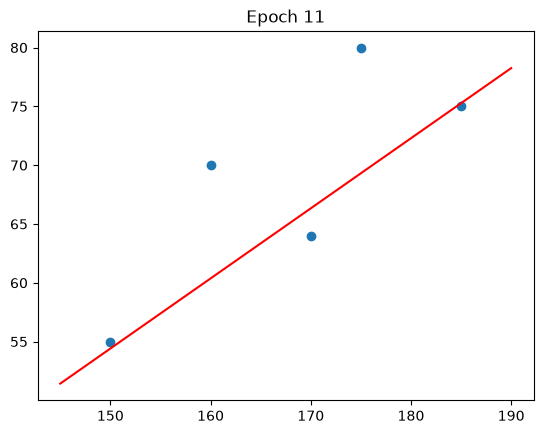

--------------------
Epoch : 12, train loss : 42.5591
Weight : 0.5997, Bias : -34.9991


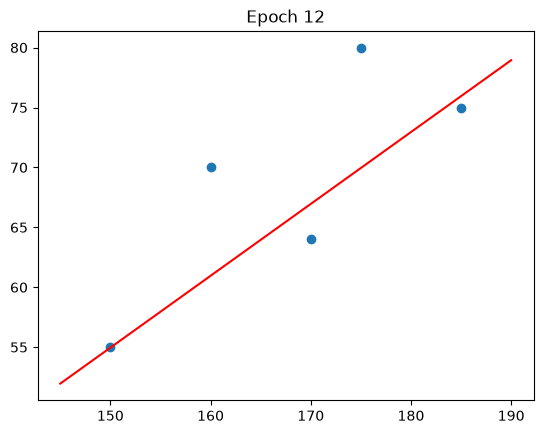

--------------------
Epoch : 13, train loss : 38.4676
Weight : 0.6028, Bias : -34.9991


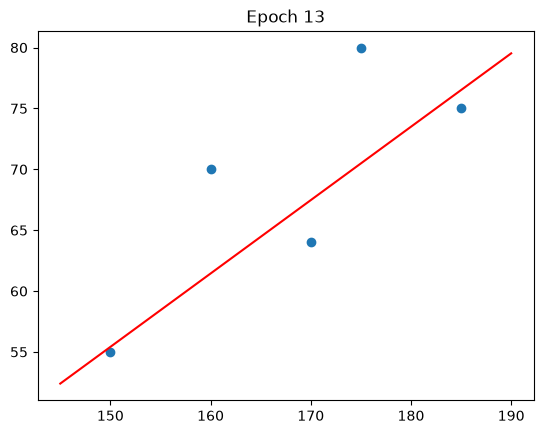

--------------------
Epoch : 14, train loss : 35.6504
Weight : 0.6053, Bias : -34.9991


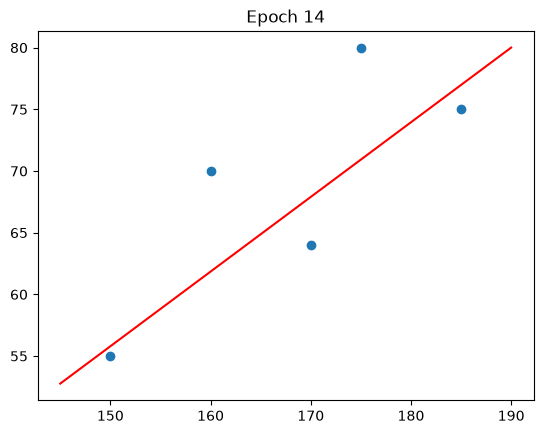

--------------------
Epoch : 15, train loss : 33.7107
Weight : 0.6074, Bias : -34.9991


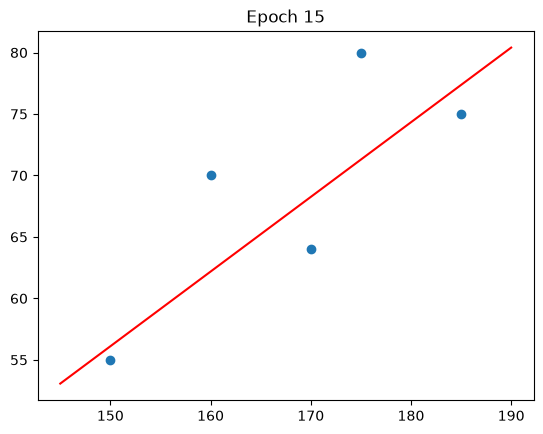

--------------------
Epoch : 16, train loss : 32.3752
Weight : 0.6091, Bias : -34.9991


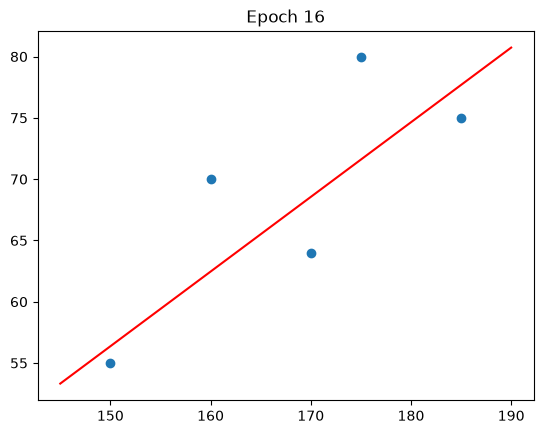

--------------------
Epoch : 17, train loss : 31.4557
Weight : 0.6106, Bias : -34.9990


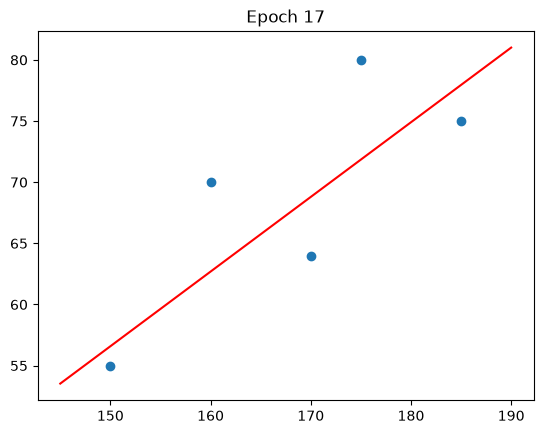

--------------------
Epoch : 18, train loss : 30.8226
Weight : 0.6118, Bias : -34.9990


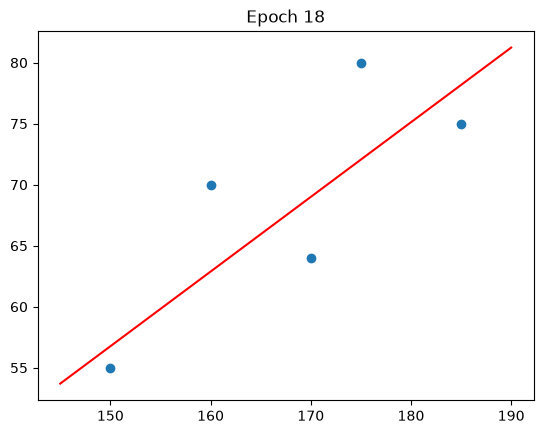

--------------------
Epoch : 19, train loss : 30.3866
Weight : 0.6127, Bias : -34.9990


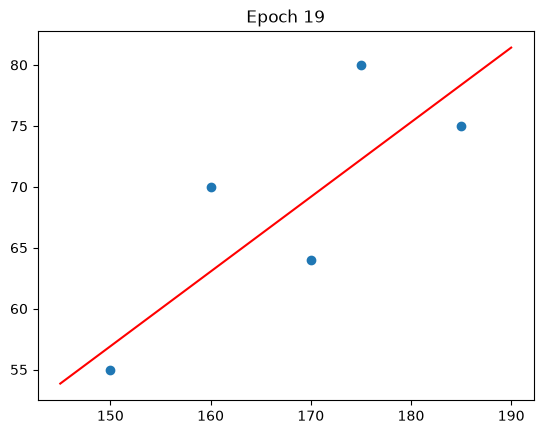

--------------------
Epoch : 20, train loss : 30.0865
Weight : 0.6136, Bias : -34.9990


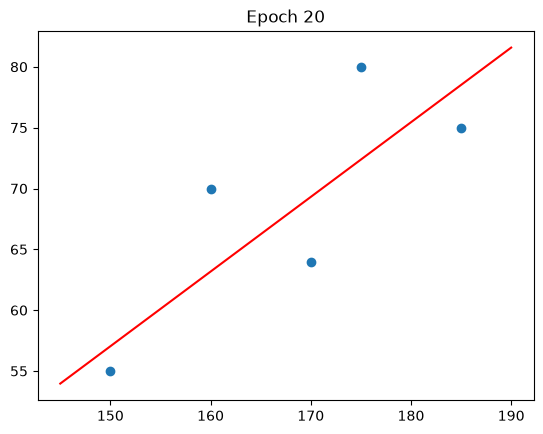

--------------------


In [16]:
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)

LR = 3e-6  # 0.000003
EPOCH = 20

loss_history = []

for ep in range(EPOCH) :
    y_hat = a * x + b

    loss = 0
    for n in range(N):
        loss += (y[n] - y_hat[n])**2
    loss = loss/N

    loss.backward()

    with torch.no_grad() :
        a -= LR * a.grad
        b -= LR * b.grad

    a.grad = torch.tensor([0.])
    b.grad = torch.tensor([0.])

    loss_history += [loss.item()]

    print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    print(f'Weight : {a.item():.4f}, Bias : {b.item():.4f}')

    x_plot = torch.linspace(145, 190, 100)
    y_plot = a.detach() * x_plot + b.detach()
    plt.figure()
    plt.plot(x, y, 'o')
    plt.plot(x_plot, y_plot, 'r')
    plt.title(f'Epoch {ep+1}')
    plt.show()

    print('-'*20)